# Variance reduction below the randomization grain
### A toy Airbnb example: cancellations in July

**The claim.** CUPED cuts variance by subtracting the part of the outcome you could have
predicted anyway. The usual version predicts each market from that market's own past. But the
covariate only has to be unaffected by the treatment. It does not have to come from the past,
and it does not have to be built at the market level. You can predict every *booking* and
average the predictions up to the market.

**The setting.** Airbnb tests a host-side reliability program meant to reduce cancellations.
When a host cancels, the guest rebooks with another host in the same market, so one host's
behavior changes other hosts' outcomes. Treating some hosts in a market but not others would
contaminate the comparison, so the program is tested market by market: 60 markets, 30 get it.

```
randomization unit : market     60
observation unit   : booking    2,500 per market in July
metric             : cancel rate
```

**The catch is timing.** The pre-period is spring, mostly solo and business travelers. The
test runs in July, when families arrive, and they arrive in beach towns far more than in
business cities. Families book bigger homes, further ahead, and both of those cancel more.

*Source: Camelo, Kearns, Cersosimo & Drerup (2026), "Variance Reduction Below the
Randomization Grain," tech-at-instacart. All data here is simulated.*

In [1]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

# Colab downloads the CSV from GitHub. A local copy next to the notebook is used if present.
DATA_URL = ("https://raw.githubusercontent.com/wolverinenyc/WhatsTheImpact/main/"
            "tutorials/data/airbnb_cancellations.csv.gz")
local = [p for p in ["data/airbnb_cancellations.csv.gz", "../data/airbnb_cancellations.csv.gz"]
         if os.path.exists(p)]
df = pd.read_csv(local[0] if local else DATA_URL)
df["multi_br"] = (df.home_type == "multi_br").astype(int)

FEATURES = ["multi_br", "lead_time_days"]
spring = df[df.period == "spring"].reset_index(drop=True)
july = df[df.period == "july"].reset_index(drop=True)
N_MARKETS = df.market.nunique()

GREY, BLUE, GREEN, ORANGE = "#8a8a8a", "#2a78d6", "#1baf7a", "#eb6834"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10.5, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .3,
                     "legend.frameon": False, "axes.titleweight": "semibold"})
os.makedirs("figures", exist_ok=True)

print(f"{len(spring):,} spring bookings, {len(july):,} July bookings, {N_MARKETS} markets")

90,000 spring bookings, 150,000 July bookings, 60 markets


## The data

One row per booking:

```
home_type        1br or multi_br
lead_time_days   days between booking and check-in
cancelled        whether the booking was cancelled
p0, p1           the true cancel probability without / with the program
```

`p0` and `p1` exist only because this is a simulation. They are what lets us check every
answer against a known truth, and no estimator below uses them.

Notice what is *not* in the data: whether the guest is a family. You see what people book,
not who they are.

In [2]:
july.head()

,market,period,home_type,lead_time_days,p0,p1,cancelled,multi_br
0,0,july,multi_br,49,0.26282,0.23481,0,1
1,0,july,multi_br,70,0.29233,0.26229,0,1
2,0,july,multi_br,9,0.17734,0.15651,1,1
3,0,july,1br,11,0.11269,0.09854,0,0
4,0,july,multi_br,38,0.24443,0.21780,0,1


## 1. July is a different crowd, and a different crowd in every market

Each line is one market, moving from its spring share of multi-bedroom bookings (grey) to its
July share (color). In spring every market looks about the same. In July the beach towns flip
and the business cities barely move.

That market-by-market difference is what makes the method work. If every market shifted by the
same amount, the shift would be absorbed by the intercept and spring's numbers would still rank
the markets correctly.

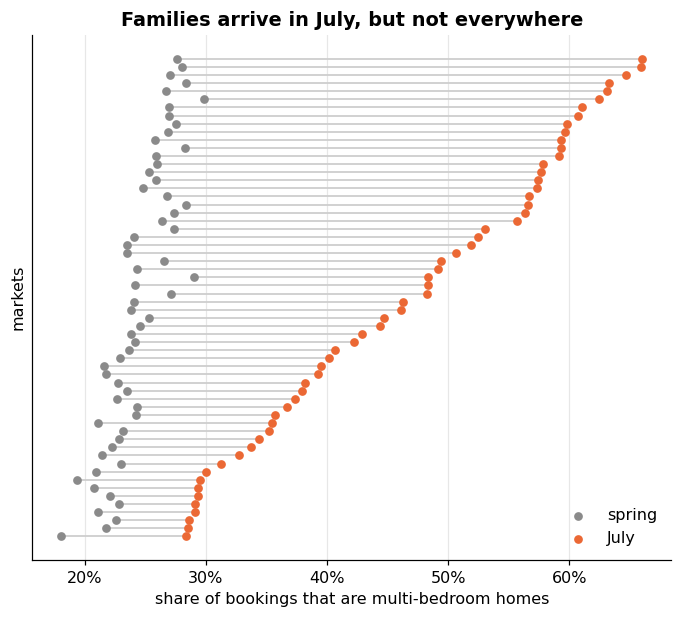

multi-bedroom share across markets, spring: 18% to 30%
multi-bedroom share across markets, July:   28% to 66%


In [3]:
by_mkt = pd.DataFrame({"spring": spring.groupby("market").multi_br.mean(),
                       "july": july.groupby("market").multi_br.mean()}).sort_values("july")
y = np.arange(N_MARKETS)

fig, ax = plt.subplots(figsize=(7.5, 6.2))
ax.hlines(y, by_mkt.spring, by_mkt.july, color="#cfcfcf", lw=1.2)
ax.scatter(by_mkt.spring, y, color=GREY, s=22, label="spring", zorder=3)
ax.scatter(by_mkt.july, y, color=ORANGE, s=22, label="July", zorder=3)
ax.set(yticks=[], xlabel="share of bookings that are multi-bedroom homes", ylabel="markets",
       title="Families arrive in July, but not everywhere")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
fig.savefig("figures/1_july_shift.png", bbox_inches="tight"); plt.show()

print(f"multi-bedroom share across markets, spring: {by_mkt.spring.min():.0%} to {by_mkt.spring.max():.0%}")
print(f"multi-bedroom share across markets, July:   {by_mkt.july.min():.0%} to {by_mkt.july.max():.0%}")

## 2. Learn what cancels, using spring

Families are not flagged, but what they book is: bigger homes, booked further ahead. Both
cancel more, and that relationship is the same in spring as in July. Only the mix changes.

In [4]:
lead_bucket = pd.cut(spring.lead_time_days, [-1, 7, 30, 90, 400],
                     labels=["0-7 days", "8-30", "31-90", "90+"])
profile = spring.pivot_table(index="home_type", columns=lead_bucket, values="cancelled",
                             aggfunc="mean", observed=True)
print("spring cancel rate, by home type and lead time\n")
print(profile.map(lambda v: f"{v:.1%}").to_string())

spring cancel rate, by home type and lead time

lead_time_days 0-7 days   8-30  31-90    90+
home_type                                   
1br                8.9%  10.4%  12.7%  18.0%
multi_br          14.8%  17.3%  23.4%  30.7%


Now fit a model of `P(cancel | home type, lead time)` on spring bookings only, then freeze it.
It is an ordinary gradient-boosted classifier. Nothing about the method needs it to be good. It
only needs to be fixed before the test starts, so the program has no way to leak into it.

Then score every July booking and average the predictions within each market.

In [5]:
model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=0)
train = np.random.default_rng(0).random(len(spring)) < 0.7
model.fit(spring.loc[train, FEATURES], spring.cancelled[train])
auc = roc_auc_score(spring.cancelled[~train], model.predict_proba(spring.loc[~train, FEATURES])[:, 1])
print(f"held-out AUC on spring bookings: {auc:.3f}")

july["prediction"] = model.predict_proba(july[FEATURES])[:, 1]   # score only, never refit

# everything from here on happens at the market level: 60 rows
mkt = july.market.values
def market_mean(values, markets=mkt):
    return np.bincount(markets, weights=np.asarray(values, float)) / np.bincount(markets)

spring_rate    = market_mean(spring.cancelled, spring.market.values)   # standard CUPED covariate
avg_prediction = market_mean(july.prediction)                          # booking-level covariate

held-out AUC on spring bookings: 0.605


An AUC of about 0.6 is a weak model: whether any individual booking cancels is mostly noise.
That turns out not to matter. Averaged over 2,500 bookings per market, the noise cancels out
and the *mix* is what remains.

## 3. Two candidate covariates

Both panels have the same 60 markets and the same y-axis: each market's July cancel rate. The
only difference is the covariate on the x-axis.

- **Left, standard CUPED:** the market's spring cancel rate. It knows each market's
  personality, but it describes a crowd that has since left.
- **Right, booking-level CUPED:** the market's average predicted cancel probability across its
  actual July bookings. It knows who showed up.

CUPED removes the part of the outcome that the covariate explains, so a tighter cloud means
more variance removed.

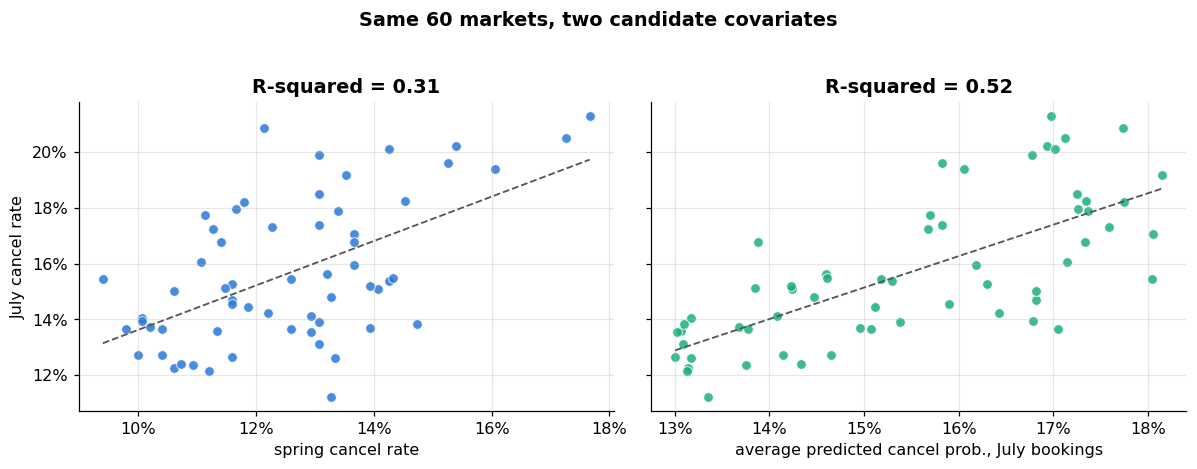

In [6]:
july_rate = market_mean(july.p0)       # July cancel rate without the program (simulation truth)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.1), sharey=True)
for a, x, name, c in [(ax[0], spring_rate, "spring cancel rate", BLUE),
                      (ax[1], avg_prediction, "average predicted cancel prob., July bookings", GREEN)]:
    r2 = np.corrcoef(x, july_rate)[0, 1] ** 2
    a.scatter(x, july_rate, color=c, s=40, alpha=.85, edgecolor="white", lw=.6)
    k = np.polyfit(x, july_rate, 1); xs = np.linspace(x.min(), x.max(), 20)
    a.plot(xs, np.polyval(k, xs), color="#555", lw=1.2, ls="--")
    a.set(xlabel=name, title=f"R-squared = {r2:.2f}")
    a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax[0].set_ylabel("July cancel rate")
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle("Same 60 markets, two candidate covariates", y=1.03, fontweight="semibold")
fig.tight_layout(); fig.savefig("figures/2_covariates.png", bbox_inches="tight"); plt.show()

## 4. Three estimators

All three are the same regression on the 60 market rows: July cancel rate on a treatment
indicator, plus at most one covariate.

```
naive                  no covariate                              difference in means
standard CUPED         spring cancel rate                        the market's own past
booking-level CUPED    average prediction over July bookings     the method
```

Here is one test: randomize 30/30 once and run all three.

In [7]:
COVARIATES = {"naive": None,
              "standard CUPED": spring_rate[:, None],
              "booking-level CUPED": avg_prediction[:, None]}

def estimate(Y, T, X):
    D = T[:, None] if X is None else np.column_stack([T, X])
    fit = sm.OLS(Y, sm.add_constant(D)).fit()
    return fit.params[1], fit.bse[1]

def run_test(rng, arms=COVARIATES):
    T = np.zeros(N_MARKETS)
    T[rng.permutation(N_MARKETS)[:N_MARKETS // 2]] = 1
    p = np.where(T[mkt] == 1, july.p1, july.p0)          # treated markets get p1
    Y = market_mean(rng.random(len(july)) < p)           # observed July cancel rates
    return {name: estimate(Y, T, X) for name, X in arms.items()}

TRUE_EFFECT = (market_mean(july.p1) - market_mean(july.p0)).mean()
print(f"true effect of the program: {100*TRUE_EFFECT:+.2f} pp\n")
print(f"{'':22}{'estimate':>10}{'std err':>10}")
for name, (b, se) in run_test(np.random.default_rng(1)).items():
    print(f"{name:22}{100*b:>+9.2f}pp{100*se:>9.2f}pp")

true effect of the program: -1.81 pp

                        estimate   std err
naive                     -1.51pp     0.65pp
standard CUPED            -1.62pp     0.56pp
booking-level CUPED       -2.08pp     0.47pp


## 5. Variance reduction

That was one test, and one test is a single draw: the estimates and their standard errors both
bounce around from one randomization to the next. So hold the 60 markets fixed, re-randomize
the 30/30 split 500 times, redraw the outcomes each time, and measure how much each estimator
moves.

```
variance reduction  =  1 - Var(estimator) / Var(naive)
```

In [8]:
ARMS = {**COVARIATES, "both covariates": np.column_stack([spring_rate, avg_prediction])}
rng = np.random.default_rng(2024)
draws = {name: [] for name in ARMS}
for _ in range(500):
    for name, (b, _) in run_test(rng, ARMS).items():
        draws[name].append(b)
draws = {k: np.array(v) for k, v in draws.items()}
vr = {k: 1 - d.var() / draws["naive"].var() for k, d in draws.items()}

results = pd.DataFrame({
    "average estimate":   [f"{100*draws[k].mean():+.2f} pp" for k in COVARIATES],
    "bias":               [f"{100*(draws[k].mean() - TRUE_EFFECT):+.3f} pp" for k in COVARIATES],
    "std dev":            [f"{100*draws[k].std():.2f} pp" for k in COVARIATES],
    "variance reduction": [f"{vr[k]:.1%}" for k in COVARIATES],
}, index=list(COVARIATES))
print(f"true effect {100*TRUE_EFFECT:+.2f} pp, 500 re-randomizations\n")
print(results.to_string())
print()
for k in ["standard CUPED", "booking-level CUPED"]:
    print(f"{k}: same precision as naive with {N_MARKETS * (1 - vr[k]):.0f} of {N_MARKETS} markets")
print(f"\nusing both covariates together: {vr['both covariates']:.1%} variance reduction")

true effect -1.81 pp, 500 re-randomizations

                    average estimate       bias  std dev variance reduction
naive                       -1.80 pp  +0.011 pp  0.65 pp               0.0%
standard CUPED              -1.78 pp  +0.034 pp  0.55 pp              28.1%
booking-level CUPED         -1.81 pp  +0.007 pp  0.46 pp              50.8%

standard CUPED: same precision as naive with 43 of 60 markets
booking-level CUPED: same precision as naive with 30 of 60 markets

using both covariates together: 66.2% variance reduction


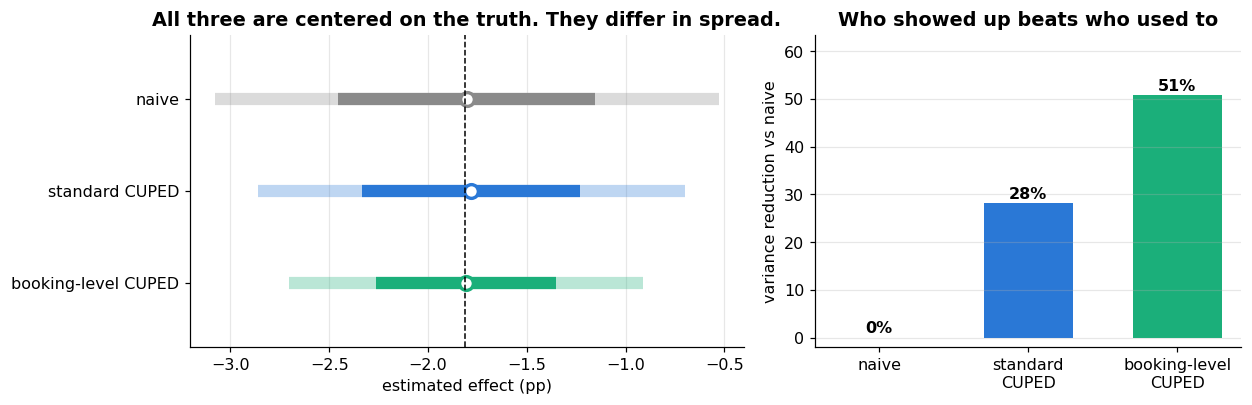

In [9]:
names, cols = list(COVARIATES), [GREY, BLUE, GREEN]
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})

for k, (name, c) in enumerate(zip(names, cols)):
    d = 100 * draws[name]; yk = 2 - k
    ax[0].plot([d.mean() - 1.96*d.std(), d.mean() + 1.96*d.std()], [yk, yk], color=c, lw=8,
               alpha=.3, solid_capstyle="butt")
    ax[0].plot([d.mean() - d.std(), d.mean() + d.std()], [yk, yk], color=c, lw=8,
               solid_capstyle="butt")
    ax[0].plot(d.mean(), yk, "o", color="white", mec=c, mew=2.2, ms=9)
ax[0].axvline(100 * TRUE_EFFECT, color="black", lw=1, ls="--")
ax[0].set(yticks=[2, 1, 0], yticklabels=names, xlabel="estimated effect (pp)", ylim=(-.7, 2.7),
          title="All three are centered on the truth. They differ in spread.")
ax[0].grid(axis="y", visible=False)

v = [100 * vr[n] for n in names]
ax[1].bar(range(3), v, color=cols, width=.6)
for x, val in enumerate(v):
    ax[1].text(x, val + 1, f"{val:.0f}%", ha="center", fontweight="semibold")
ax[1].set(xticks=range(3), xticklabels=["naive", "standard\nCUPED", "booking-level\nCUPED"],
          ylabel="variance reduction vs naive", ylim=(min(0, min(v)) - 2, max(v) * 1.25),
          title="Who showed up beats who used to")
ax[1].grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig("figures/3_result.png", bbox_inches="tight"); plt.show()

## What to take away

- **CUPED only needs a covariate the treatment cannot affect.** It does not have to come from
  the pre-period, and it does not have to be built at the market level.
- **Spring's cancel rate and July's bookings know different things.** Spring knows each
  market's persistent personality. July's bookings know who actually showed up. That is why
  using both does better than either alone.
- **It only helps when the mix shifts differently across markets.** If every market had gained
  families equally, the shift would wash out and the booking-level covariate would add almost
  nothing.
- **The treatment must not change who books.** A host program guests never see is fine. A more
  generous guest cancellation policy would attract families, and then July's mix would itself
  be an outcome of the treatment. The check is cheap: average predicted cancel probability
  should be the same in treated and control markets.
- **With two features you could hand-build this.** July's multi-bedroom share and average lead
  time would get you most of the way. The model's value is that it does the same thing
  automatically when there are dozens of booking features.
- **This is one simulated dataset.** A different draw of 60 markets gives different
  magnitudes. The ordering is what is stable.